# Neurons, Layers and the Forward Pass in NumPy, Line by Line

**Neural Network Lab · CSIT843A Lecture 6** · College of Computer Studies, University of Technology Bahrain  
Prepared by **Eng. Saeed Serwan Abdulsattar**

Interactive version with hover-to-explain code: **https://saeedserwan.github.io/NeuralNetwork/code-network.html**

A complete, runnable notebook for chapters 2–3. Compute a neuron by hand, plot sigmoid and ReLU, load the MNIST digits, build the 784 → 16 → 16 → 10 network, count its 13,002 parameters and run a forward pass. Only NumPy and Matplotlib are needed. Hover over (or tap) any line of code to see what it does.

**You will learn to:**

1. Compute one neuron: weighted sum, bias, sigmoid
2. Plot sigmoid and ReLU and their slopes
3. Load MNIST and look at the pictures as numbers
4. Build the 784 → 16 → 16 → 10 network and count its parameters
5. Run a forward pass and compute the cost of one example

> Run the cells from top to bottom (Shift + Enter). After each code cell, a **Line by line** note explains what every line does.

## 1. Import the libraries

**NumPy** for arrays and maths, **Matplotlib** for pictures and charts. No deep-learning library: every step is written out by hand.

In [1]:
%config InlineBackend.figure_format = "retina"
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#ececec"

**Line by line**

1. `%config InlineBackend.figure_format = "retina"`  
   A Jupyter setting (not Python): sharper plots on high-resolution screens.
2. `import numpy as np`  
   NumPy: arrays and maths. `np` is the standard nickname.
3. `import matplotlib.pyplot as plt`  
   Matplotlib's plotting interface.
4. `plt.rcParams["figure.figsize"] = (7, 4)`  
   Default figure size (width, height) in inches.
5. `plt.rcParams["axes.spines.top"] = False` …  
   A cleaner look: hide the top and right borders of every chart.
6. `plt.rcParams["axes.grid"] = True` …  
   Light grid lines make values easier to read.

## 2. One neuron by hand

The spam neuron of Exercise 1: each word present gives the input 1, absent gives 0. The neuron computes $\sigma(w_1x_1 + w_2x_2 + w_3x_3 + w_4x_4 + b)$.

In [2]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

words = ["prize", "money", "dear", "win"]
w = np.array([2.0, 1.5, -1.0, 1.0])
b = -1.5

x = np.array([0, 1, 1, 0])
z = w @ x + b
print("weighted sum + bias:", z, " sigma:", round(sigmoid(z), 2))
print("spam?", sigmoid(z) >= 0.5)

x2 = np.array([1, 1, 1, 0])
print("with 'prize':", round(sigmoid(w @ x2 + b), 2))

weighted sum + bias: -1.0  sigma: 0.27
spam? False
with 'prize': 0.73


**Line by line**

1. `def sigmoid(z):`  
   The squishing function σ(z) = 1 / (1 + e^(−z)).
2. `return 1 / (1 + np.exp(-z))`  
   np.exp works on single numbers and on whole arrays.
3. `words = ["prize", "money", "dear", "win"]`  
   The four words the neuron looks for.
4. `w = np.array([2.0, 1.5, -1.0, 1.0])`  
   One weight per word: positive words push towards spam, “dear” pushes away.
5. `b = -1.5`  
   The bias: how much evidence is needed before the neuron fires.
6. `x = np.array([0, 1, 1, 0])`  
   The email contains only “money” and “dear”.
7. `z = w @ x + b`  
   `@` is the dot product: 2·0 + 1.5·1 − 1·1 + 1·0, then add the bias.
8. `print("weighted sum + bias:", z, " sigma:", round(sigmoid(z), 2))`  
   −1.0 and σ(−1) = 0.27.
9. `print("spam?", sigmoid(z) >= 0.5)`  
   Below 0.5, so not spam.
10. `x2 = np.array([1, 1, 1, 0])`  
   Add the word “prize”.
11. `print("with 'prize':", round(sigmoid(w @ x2 + b), 2))`  
   The sum becomes 1.0 and σ = 0.73: spam.

## 3. Activation functions

Sigmoid squishes into 0 … 1; ReLU keeps positive numbers and turns negative ones into 0. The dashed lines are the **slopes**: the sigmoid’s is never above 0.25.

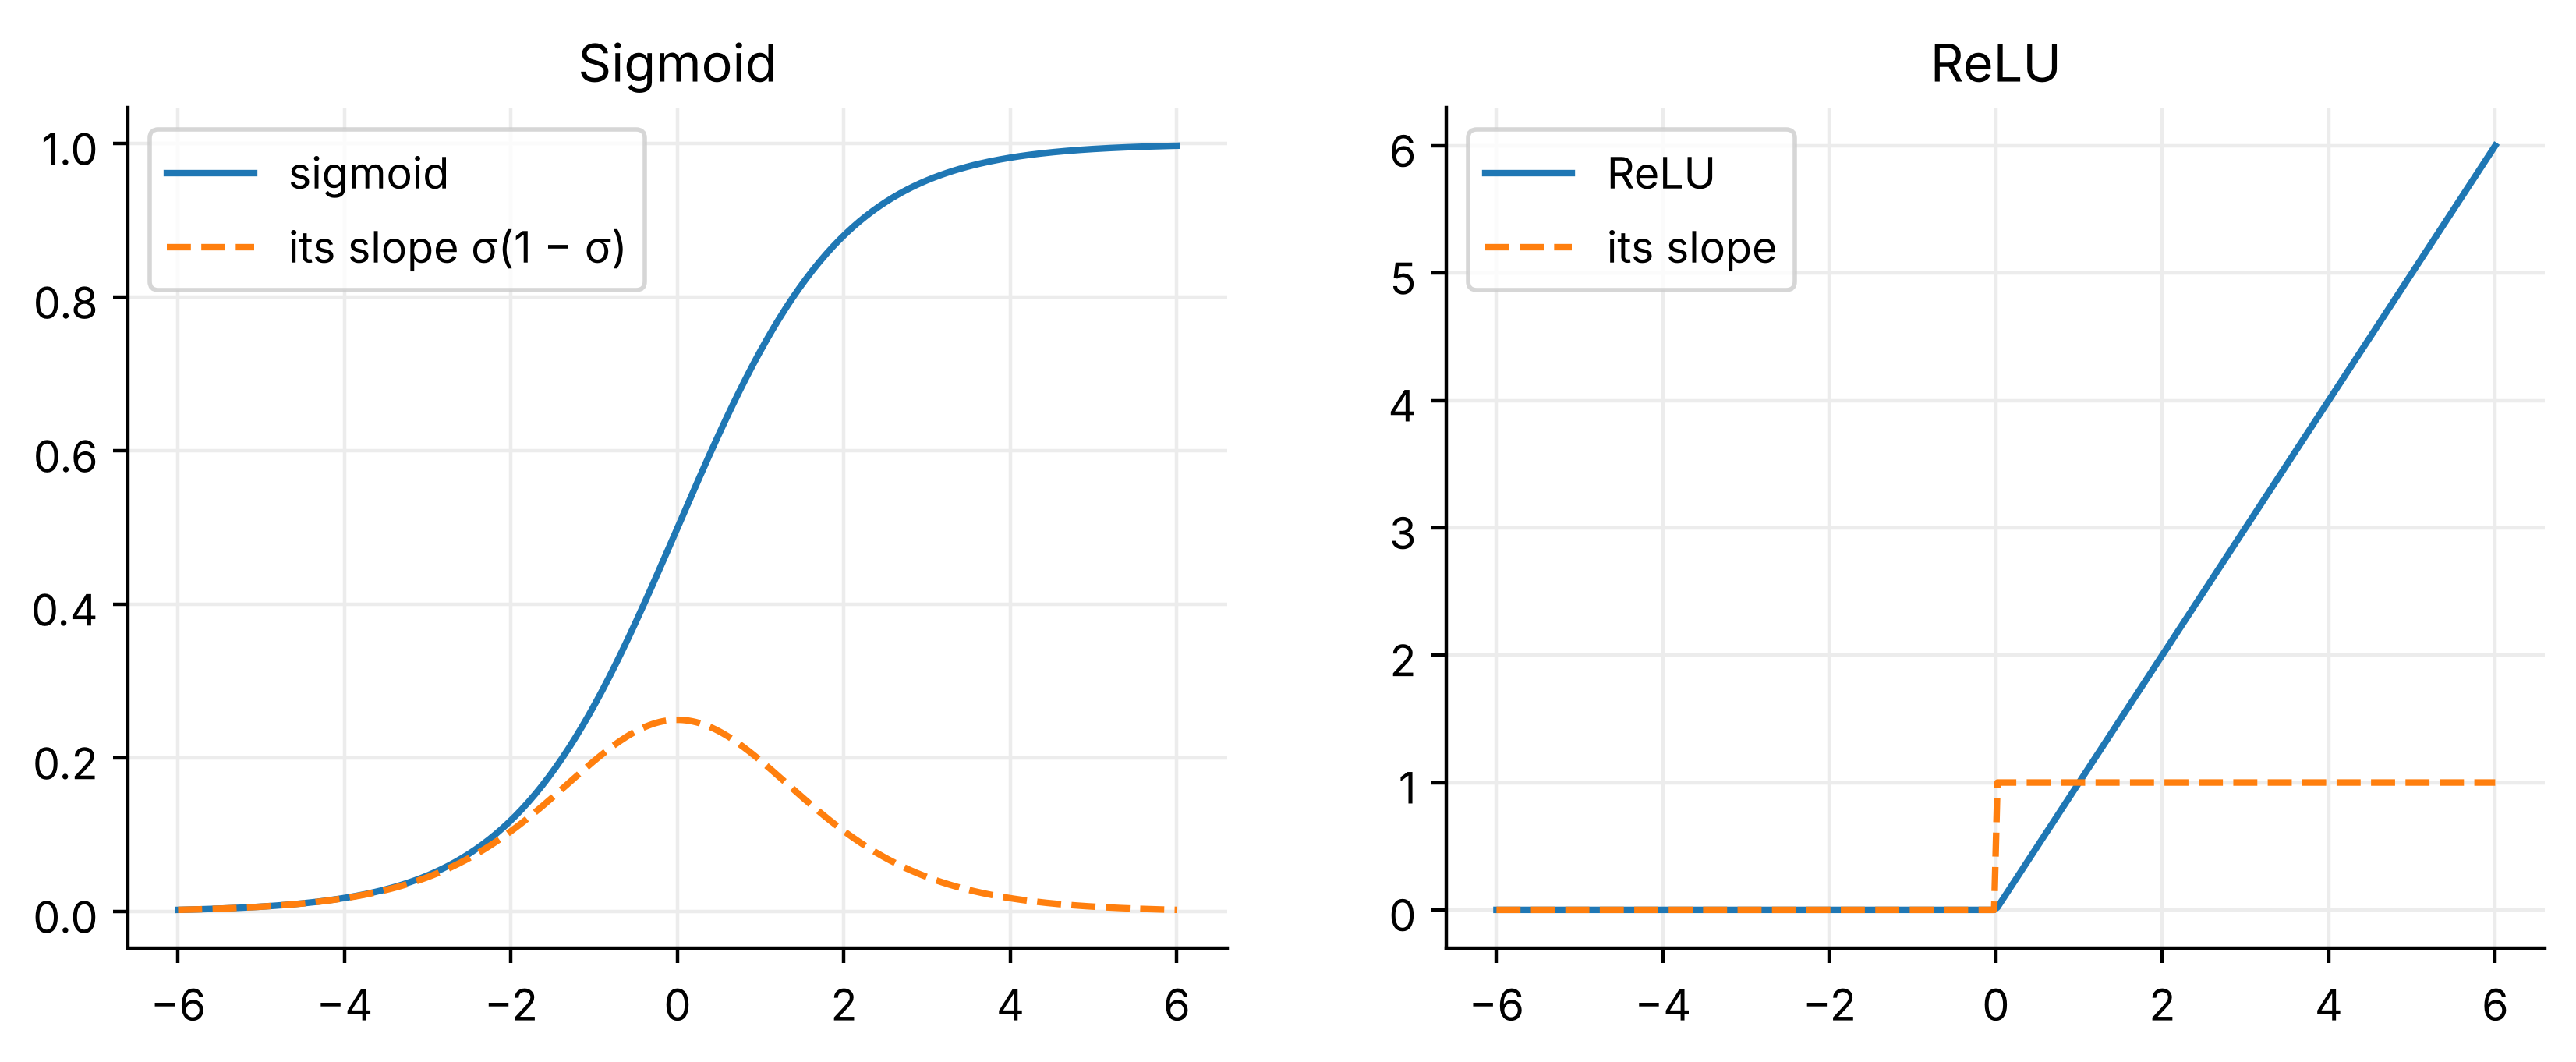

largest sigmoid slope: 0.25


In [3]:
z = np.linspace(-6, 6, 300)
s = sigmoid(z)
relu = np.maximum(0, z)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(z, s, label="sigmoid")
ax[0].plot(z, s * (1 - s), "--", label="its slope σ(1 − σ)")
ax[0].legend(); ax[0].set_title("Sigmoid")
ax[1].plot(z, relu, label="ReLU")
ax[1].plot(z, (z > 0).astype(float), "--", label="its slope")
ax[1].legend(); ax[1].set_title("ReLU")
plt.show()
print("largest sigmoid slope:", (s * (1 - s)).max().round(3))

**Line by line**

1. `z = np.linspace(-6, 6, 300)`  
   300 evenly spaced values of z from −6 to 6.
2. `s = sigmoid(z)`  
   σ for every value at once.
3. `relu = np.maximum(0, z)`  
   ReLU(z) = max(0, z), element by element.
4. `fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))`  
   Two charts side by side.
5. `ax[0].plot(z, s, label="sigmoid")`  
   The S-shaped curve.
6. `ax[0].plot(z, s * (1 - s), "--", label="its slope σ(1 − σ)")` …  
   The slope of the sigmoid; its peak is 0.25 at z = 0.
7. `ax[1].plot(z, relu, label="ReLU")`  
   A hinge: flat at 0, then a straight line.
8. `ax[1].plot(z, (z > 0).astype(float), "--", label="its slope")` …  
   The slope of ReLU: 0 or 1.
9. `plt.show()`  
   Draw the figure.
10. `print("largest sigmoid slope:", (s * (1 - s)).max().round(3))`  
   0.25: remember it for vanishing gradients.

## 4. Load the handwritten digits

MNIST: 70,000 pictures of 28 × 28 pixels. Each picture becomes a row of 784 numbers between 0 (black) and 1 (white).

In [4]:
import gzip, os, urllib.request

URL = "https://raw.githubusercontent.com/fgnt/mnist/master/"

def load(name, offset):
    if not os.path.exists(name):
        urllib.request.urlretrieve(URL + name, name)
    with gzip.open(name) as f:
        return np.frombuffer(f.read(), np.uint8, offset=offset)

X_train = load("train-images-idx3-ubyte.gz", 16).reshape(-1, 784) / 255
y_train = load("train-labels-idx1-ubyte.gz", 8)
X_test = load("t10k-images-idx3-ubyte.gz", 16).reshape(-1, 784) / 255
y_test = load("t10k-labels-idx1-ubyte.gz", 8)
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(60000, 784) (60000,) (10000, 784) (10000,)


**Line by line**

1. `import gzip, os, urllib.request`  
   Standard-library tools to download and unzip the data files.
2. `URL = "https://raw.githubusercontent.com/fgnt/mnist/master/"`  
   A public copy of the MNIST files on GitHub.
3. `def load(name, offset):`  
   Download one MNIST file (once) and read it as bytes.
4. `if not os.path.exists(name):` …  
   Only download if we do not have the file yet.
5. `with gzip.open(name) as f:`  
   The files are gzip-compressed.
6. `return np.frombuffer(f.read(), np.uint8, offset=offset)`  
   Skip the header (16 bytes for images, 8 for labels) and read the rest as numbers 0–255.
7. `X_train = load("train-images-idx3-ubyte.gz", 16).reshape(-1, 784) / 255`  
   60,000 training pictures, each a row of 784 pixels, scaled to 0 … 1.
8. `y_train = load("train-labels-idx1-ubyte.gz", 8)`  
   Their labels: the digit 0–9 each picture shows.
9. `X_test = load("t10k-images-idx3-ubyte.gz", 16).reshape(-1, 784) / 255` …  
   10,000 test pictures the network never trains on.
10. `print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)`  
   Check the sizes.

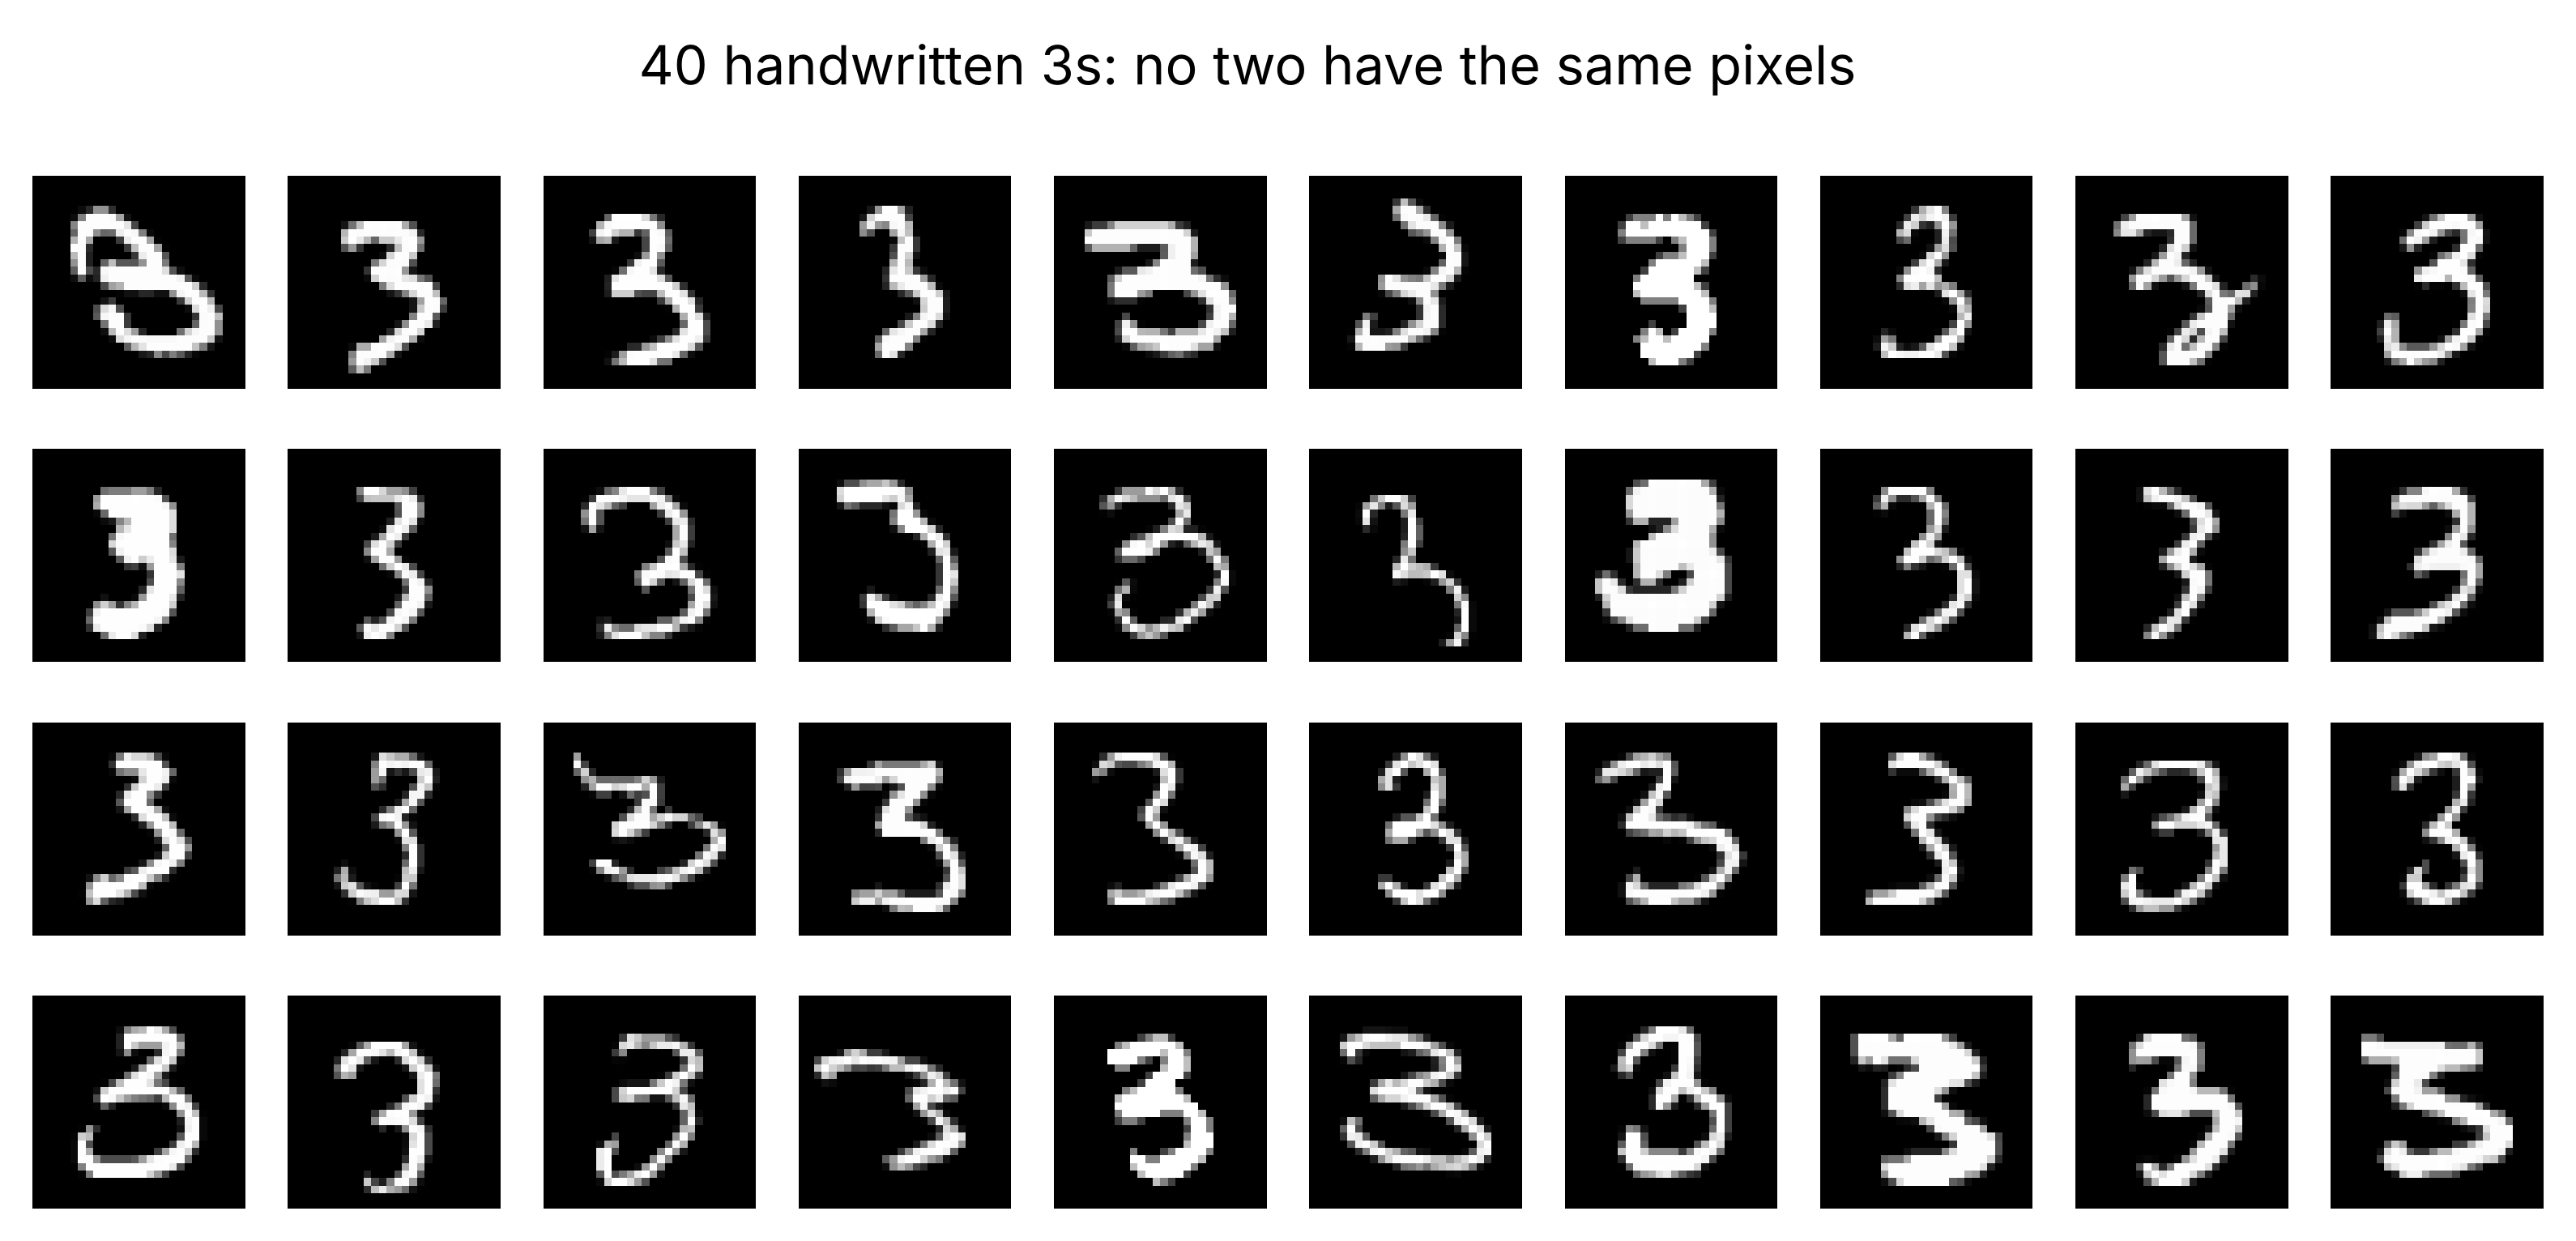

one picture as numbers (rows 10 to 13, columns 8 to 20):
[[0.  0.  0.  0.  0.  0.2 0.9 1.  1.  0.3 0.  0. ]
 [0.  0.4 0.7 0.3 0.3 0.3 0.6 1.  1.  0.5 0.  0. ]
 [0.2 1.  1.  1.  1.  1.  1.  1.  1.  0.9 0.3 0.1]
 [0.1 0.9 1.  1.  1.  1.  1.  1.  1.  1.  1.  1. ]]


In [5]:
threes = X_test[y_test == 3][:40]
fig, axes = plt.subplots(4, 10, figsize=(10, 4.2))
for img, ax in zip(threes, axes.ravel()):
    ax.imshow(img.reshape(28, 28), cmap="gray")
    ax.axis("off")
plt.suptitle("40 handwritten 3s: no two have the same pixels")
plt.show()

print("one picture as numbers (rows 10 to 13, columns 8 to 20):")
print(np.round(threes[0].reshape(28, 28)[10:14, 8:20], 1))

**Line by line**

1. `threes = X_test[y_test == 3][:40]`  
   The first 40 test pictures that show a 3.
2. `fig, axes = plt.subplots(4, 10, figsize=(10, 4.2))`  
   A grid of 4 × 10 small pictures.
3. `for img, ax in zip(threes, axes.ravel()):`  
   Pair each picture with one small chart.
4. `ax.imshow(img.reshape(28, 28), cmap="gray")`  
   Turn the 784 numbers back into a 28 × 28 square.
5. `ax.axis("off")`  
   No axes around the pictures.
6. `plt.suptitle("40 handwritten 3s: no two have the same pixels")` …  
   One title for the whole grid.
7. `print("one picture as numbers (rows 10 to 13, columns 8 to 20):")` …  
   Peek at the numbers the network will receive.

## 5. Build the 784 → 16 → 16 → 10 network

One weight matrix and one bias vector per connection between layers. Row k of a weight matrix holds the weights of neuron k. All start as small random numbers.

In [6]:
sizes = [784, 16, 16, 10]
rng = np.random.default_rng(0)

W = [rng.normal(0, 1 / np.sqrt(n_in), (n_out, n_in))
     for n_in, n_out in zip(sizes[:-1], sizes[1:])]
b = [np.zeros(n_out) for n_out in sizes[1:]]

for i, (Wi, bi) in enumerate(zip(W, b)):
    print(f"layer {i+1}: W {Wi.shape}, b {bi.shape}, parameters {Wi.size + bi.size:,}")
print("total parameters:", f"{sum(Wi.size + bi.size for Wi, bi in zip(W, b)):,}")

layer 1: W (16, 784), b (16,), parameters 12,560
layer 2: W (16, 16), b (16,), parameters 272
layer 3: W (10, 16), b (10,), parameters 170
total parameters: 13,002


**Line by line**

1. `sizes = [784, 16, 16, 10]`  
   Input, two hidden layers, output.
2. `rng = np.random.default_rng(0)`  
   A random number generator with a fixed seed, so results repeat.
3. `W = [rng.normal(0, 1 / np.sqrt(n_in), (n_out, n_in))` …  
   One matrix per connection, shape (neurons out, neurons in). Scaling by 1/√inputs keeps the sums a sensible size.
4. `b = [np.zeros(n_out) for n_out in sizes[1:]]`  
   One bias per neuron, starting at 0.
5. `for i, (Wi, bi) in enumerate(zip(W, b)):` …  
   Show the shapes and count the knobs, layer by layer.
6. `print("total parameters:", f"{sum(Wi.size + bi.size for Wi, bi in zip(W, b)):,}")`  
   13,002.

## 6. The forward pass

Each layer is $a^{(1)} = \sigma\big(W a^{(0)} + b\big)$. Three matrix multiplications, three sigmoids, and the 784 pixels have become 10 numbers.

In [7]:
def forward(x):
    a = x
    for Wi, bi in zip(W, b):
        a = sigmoid(a @ Wi.T + bi)
    return a

out = forward(X_test[0])
print("label:", y_test[0])
print("outputs:", np.round(out, 2))
print("answer:", out.argmax())

label: 7
outputs: [0.56 0.41 0.58 0.65 0.54 0.59 0.61 0.57 0.69 0.28]
answer: 8


**Line by line**

1. `def forward(x):`  
   Run one picture (or a whole batch of pictures) through the network.
2. `a = x`  
   The input layer: the pixels themselves.
3. `for Wi, bi in zip(W, b):`  
   For each layer in turn …
4. `a = sigmoid(a @ Wi.T + bi)`  
   … weighted sums of all neurons at once (a matrix multiply), add the biases, squish.
5. `return a`  
   The 10 output activations.
6. `out = forward(X_test[0])`  
   The first test picture.
7. `print("label:", y_test[0])`  
   What the picture really shows.
8. `print("outputs:", np.round(out, 2))`  
   Ten numbers between 0 and 1, one per digit.
9. `print("answer:", out.argmax())`  
   The brightest output neuron is the answer.

## 7. How bad is a random network?

The **cost** of one example: $C = \sum_j (a_j - y_j)^2$, where $y$ is 1 for the right digit and 0 for the others. Then the accuracy over all 10,000 test pictures.

In [8]:
y = np.zeros(10); y[y_test[0]] = 1
cost = ((out - y) ** 2).sum()
print("cost of this example:", round(cost, 2))

all_out = forward(X_test)
acc = (all_out.argmax(axis=1) == y_test).mean()
Y = np.eye(10)[y_test]
print(f"accuracy of random weights: {acc:.1%}")
print("average cost:", ((all_out - Y) ** 2).sum(axis=1).mean().round(2))

cost of this example: 3.0
accuracy of random weights: 9.7%
average cost: 3.05


**Line by line**

1. `y = np.zeros(10); y[y_test[0]] = 1`  
   The wanted output: a 1 at the correct digit, 0 elsewhere (“one-hot”).
2. `cost = ((out - y) ** 2).sum()`  
   Square the differences and add them up.
3. `print("cost of this example:", round(cost, 2))`  
   Large: the random network is unsure and wrong.
4. `all_out = forward(X_test)`  
   All 10,000 test pictures in one go: a 10,000 × 10 array.
5. `acc = (all_out.argmax(axis=1) == y_test).mean()`  
   Compare each answer with the label; the mean of True/False is the fraction correct.
6. `Y = np.eye(10)[y_test]`  
   One-hot rows for all labels (row k of the identity matrix is the one-hot vector of k).
7. `print(f"accuracy of random weights: {acc:.1%}")`  
   About 10%: guessing one of 10 digits.
8. `print("average cost:", ((all_out - Y) ** 2).sum(axis=1).mean().round(2))`  
   About 3. The next notebook brings it down to 0.08.

## 8. What you built

| Piece | In code |
|---|---|
| neuron | `sigmoid(w @ x + b)` |
| layer | `sigmoid(a @ W.T + b)` |
| network | a loop over layers |
| parameters | 13,002 numbers in `W` and `b` |
| cost | `((out - y) ** 2).sum()` |

The network is a function with 13,002 knobs, all random. **Next notebook:** turn the knobs with gradient descent and backpropagation.